# DASC 5420 – Exercise 4: Resampling Methods
**Student Name:** Asmita Bashyal  
**Student Number:** T00781099



## Setup

In [1]:
import numpy as np
import statsmodels.api as sm
from matplotlib.pyplot import subplots
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize)
from functools import partial
from sklearn.model_selection import (train_test_split,
                                     cross_validate,
                                     KFold)
from ISLP.models import sklearn_sm

The bootstrap function `boot_SE()` It draws `B` bootstrap samples of size `n` with replacement, computes `func` on each one, and returns the standard deviation of the `B` estimates.

In [2]:
def boot_SE(func,
            D,
            n=None,
            B=1000,
            seed=0):
    rng = np.random.default_rng(seed)
    first_, second_ = 0, 0
    n = n or D.shape[0]
    for _ in range(B):
        idx = rng.choice(D.index,
                         n,
                         replace=True)
        value = func(D, idx)
        first_ += value
        second_ += value**2
    return np.sqrt(second_ / B - (first_ / B)**2)

## Question 1
Show that

$$\alpha = \frac{\sigma_Y^2 - \sigma_{XY}}{\sigma_X^2 + \sigma_Y^2 - 2\sigma_{XY}} \qquad (5.6)$$

minimizes $\text{Var}(\alpha X + (1-\alpha)Y)$, where $\sigma_X^2 = \text{Var}(X)$, $\sigma_Y^2 = \text{Var}(Y)$ and $\sigma_{XY} = \text{Cov}(X, Y)$.

**Step 1. Expand the variance.** Using $\text{Var}(aX + bY) = a^2\text{Var}(X) + b^2\text{Var}(Y) + 2ab\,\text{Cov}(X,Y)$:

$$f(\alpha) = \text{Var}(\alpha X + (1-\alpha)Y) = \alpha^2\sigma_X^2 + (1-\alpha)^2\sigma_Y^2 + 2\alpha(1-\alpha)\sigma_{XY}$$

**Step 2. Differentiate with respect to $\alpha$.**

$$f'(\alpha) = 2\alpha\sigma_X^2 - 2(1-\alpha)\sigma_Y^2 + 2(1 - 2\alpha)\sigma_{XY}$$

**Step 3. Set $f'(\alpha) = 0$ and solve.** Dividing by 2 and collecting the $\alpha$ terms:

$$\alpha\sigma_X^2 - \sigma_Y^2 + \alpha\sigma_Y^2 + \sigma_{XY} - 2\alpha\sigma_{XY} = 0$$

$$\alpha(\sigma_X^2 + \sigma_Y^2 - 2\sigma_{XY}) = \sigma_Y^2 - \sigma_{XY}$$

$$\alpha = \frac{\sigma_Y^2 - \sigma_{XY}}{\sigma_X^2 + \sigma_Y^2 - 2\sigma_{XY}}$$

**Step 4. Check that it is a minimum.**

$$f''(\alpha) = 2\sigma_X^2 + 2\sigma_Y^2 - 4\sigma_{XY} = 2\,\text{Var}(X - Y) \ge 0$$

So $f$ is a convex (upward-opening) quadratic in $\alpha$, and the value of $\alpha$ in (5.6) minimizes $\text{Var}(\alpha X + (1-\alpha)Y)$. $\blacksquare$

## Question 2
A bootstrap sample is made by drawing $n$ observations **with replacement** from the original $n$ observations, so on every draw each observation has probability $1/n$ of being chosen.

### 2(a)
The first bootstrap observation is the jth observation with probability $1/n$, so the probability that it is **not** the jth observation is

$$1 - \frac{1}{n}.$$

### 2(b)
Because we sample with replacement, the second draw is again made from all $n$ observations and does not depend on the first draw. So the probability is again

$$1 - \frac{1}{n}.$$

### 2(c)
The jth observation is not in the bootstrap sample only if **none** of the $n$ draws picks it. Each draw misses it with probability $1 - 1/n$, and the draws are independent, so

$$P(j\text{th obs. not in sample}) = \left(1 - \frac{1}{n}\right)\times\cdots\times\left(1 - \frac{1}{n}\right) = \left(1 - \frac{1}{n}\right)^n.$$

So the probability that it **is** in the sample is $1 - (1 - 1/n)^n$.

### 2(d)–(f)
We use $1 - (1 - 1/n)^n$ for $n = 5$, $100$ and $10{,}000$.

In [3]:
for n in [5, 100, 10000]:
    print('n =', n, ': probability =', 1 - (1 - 1/n)**n)

n = 5 : probability = 0.6723199999999999
n = 100 : probability = 0.6339676587267709
n = 10000 : probability = 0.6321389535670295


- **(d)** $n = 5$: $1 - (4/5)^5 = 1 - 0.32768 = 0.672$
- **(e)** $n = 100$: $1 - (0.99)^{100} = 0.634$
- **(f)** $n = 10{,}000$: $1 - (0.9999)^{10000} = 0.632$

As $n$ grows, $(1 - 1/n)^n \to e^{-1} \approx 0.368$, so the probability approaches $1 - 1/e \approx 0.632$.

### 2(g)
Plot the probability for every integer $n$ from 1 to 100,000.

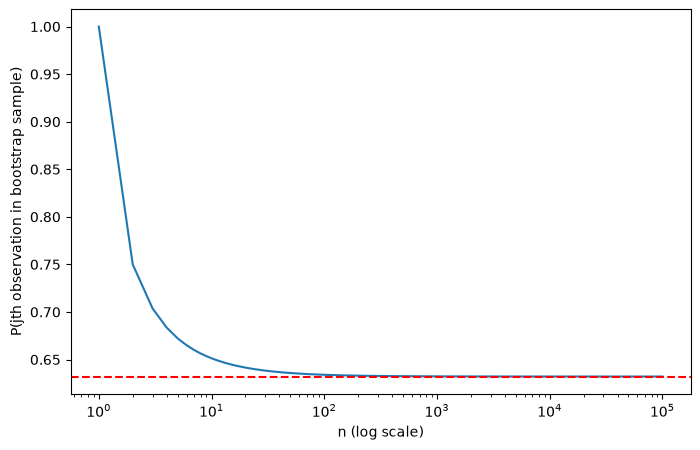

In [4]:
n = np.arange(1, 100001)
prob = 1 - (1 - 1/n)**n
fig, ax = subplots(figsize=(8, 5))
ax.plot(n, prob)
ax.set_xscale('log')
ax.axhline(1 - 1/np.e, color='red', linestyle='--')
ax.set_xlabel('n (log scale)')
ax.set_ylabel('P(jth observation in bootstrap sample)');

**Interpretation:** The x-axis is on a log scale, because on an ordinary scale the whole drop happens in the first few points. The probability is 1 at $n = 1$, falls quickly, and by about $n = 100$ it has levelled off at $1 - 1/e \approx 0.632$ (red line). So for any reasonably large data set, a bootstrap sample contains about two-thirds of the original observations.

### 2(h)
The textbook code. Note: `rng.choice(100, replace=True)` draws only **one** number, so the sample size 100 is added to draw a full bootstrap sample of size $n = 100$. Python counts from 0, so index 4 is the 5th observation.

In [5]:
rng = np.random.default_rng(10)
store = np.empty(10000)
for i in range(10000):
    store[i] = np.sum(rng.choice(100, 100, replace=True) == 4) > 0
np.mean(store)

np.float64(0.6362)

**Interpretation:** The 5th observation was in the bootstrap sample in 63.6% of the 10,000 samples. This is very close to the exact value $1 - (1 - 1/100)^{100} = 0.634$ from (e), and close to the limit $1 - 1/e \approx 0.632$. The small difference is just simulation noise, so the simulation confirms the formula: a bootstrap sample of size $n$ contains about 63% of the distinct original observations.

## Question 3
### 3(a)
$k$-fold cross-validation is implemented as follows:

1. Randomly divide the $n$ observations into $k$ groups (folds) of approximately equal size.
2. Treat the first fold as a validation set, fit the model on the remaining $k-1$ folds, and compute the mean squared error, $\text{MSE}_1$, on the observations in the held-out fold.
3. Repeat this $k$ times, each time holding out a different fold, to get $\text{MSE}_1, \dots, \text{MSE}_k$.
4. The $k$-fold CV estimate is the average

$$\text{CV}_{(k)} = \frac{1}{k}\sum_{i=1}^{k}\text{MSE}_i. \qquad (5.3)$$

For classification, the MSE is replaced by the error rate (the fraction of misclassified observations). Common choices are $k = 5$ or $k = 10$.

### 3(b)(i) Compared with the validation set approach

**Advantages of $k$-fold CV:**
- The validation set estimate of the test error can be **highly variable**, because it depends on which observations happen to land in the training and validation sets. $k$-fold CV averages over $k$ splits, so its estimate is much less variable.
- In the validation set approach only about half the observations are used to fit the model. Statistical methods tend to perform worse when trained on fewer observations, so the validation set error tends to **overestimate** the test error. In $k$-fold CV each fit uses $(k-1)n/k$ observations, so this bias is smaller.

**Disadvantages of $k$-fold CV:**
- The model has to be fitted $k$ times instead of once, so it is more expensive to compute.
- It is slightly more complicated to implement.

### 3(b)(ii) Compared with LOOCV

**Advantages of $k$-fold CV:**
- **Computation:** LOOCV needs $n$ fits, which can be very slow when $n$ is large or the model is slow to fit. $k$-fold CV with $k = 5$ or $10$ needs only 5 or 10 fits.
- **Lower variance:** In LOOCV the $n$ fitted models are trained on almost identical data, so their outputs are highly (positively) correlated, and the average of highly correlated quantities has higher variance. In $k$-fold CV the training sets overlap less, so the test error estimate usually has lower variance. Because of this bias-variance trade-off, $k = 5$ or $k = 10$ is often preferred.

**Disadvantages of $k$-fold CV:**
- **More bias:** LOOCV trains on $n-1$ observations, almost the full data set, so it gives approximately unbiased estimates of the test error. $k$-fold CV trains on fewer observations, so it has somewhat more bias.
- **Randomness:** $k$-fold CV depends on the random split into folds, while LOOCV always gives the same result.

## Question 4
We can estimate the standard deviation of our prediction using the **bootstrap**. Let $x_0$ be the particular value of $X$ and $\hat{f}(x_0)$ our prediction.

1. Draw a bootstrap data set: $n$ observations sampled **with replacement** from the original data, keeping each pair $(x_i, y_i)$ together.
2. Fit the same statistical learning method to the bootstrap data set and compute the prediction at $x_0$, call it $\hat{f}^{*1}(x_0)$.
3. Repeat steps 1–2 a large number of times $B$ (e.g. $B = 1000$), giving $\hat{f}^{*1}(x_0), \dots, \hat{f}^{*B}(x_0)$.
4. Estimate the standard deviation of the prediction by the standard deviation of these $B$ predictions:

$$\text{SE}_B(\hat{f}(x_0)) = \sqrt{\frac{1}{B-1}\sum_{r=1}^{B}\left(\hat{f}^{*r}(x_0) - \frac{1}{B}\sum_{r'=1}^{B}\hat{f}^{*r'}(x_0)\right)^2}$$

This mimics drawing new samples from the population: the bootstrap predictions show how much our prediction at $x_0$ would vary if we had collected a different training set.

## Question 5
Estimate the test error of a logistic regression for `default` (using `income` and `balance`) on the `Default` data with the validation set approach.

In [6]:
Default = load_data('Default')
Default.shape

(10000, 4)

### 5(a)

In [7]:
design = MS(['income', 'balance'])
X = design.fit_transform(Default)
y = Default['default'] == 'Yes'
glm = sm.GLM(y, X, family=sm.families.Binomial())
results = glm.fit()
summarize(results)

,coef,std err,z,P>|z|
intercept,-11.540500,0.435000,-26.544,0.0
income,0.000021,0.000005,4.174,0.0
balance,0.005600,0.000000,24.835,0.0


**Interpretation:** Both `income` and `balance` have positive coefficients with very small p-values, so both are associated with a higher probability of default. `balance` has a much larger z-statistic (24.8 vs 4.2), so it is the stronger predictor.

### 5(b)
(i) Split into a training set and a validation set (half each, random seed `random_state=0`); (ii) fit the model on the training set; (iii) classify each validation observation as `Yes` if its posterior probability of default is greater than 0.5; (iv) compute the fraction of misclassified validation observations.

In [8]:
# (i) split
Default_train, Default_valid = train_test_split(Default,
                                                test_size=5000,
                                                random_state=0)

# (ii) fit on the training set only
X_train = design.fit_transform(Default_train)
y_train = Default_train['default'] == 'Yes'
results = sm.GLM(y_train, X_train, family=sm.families.Binomial()).fit()

# (iii) posterior probabilities and predicted classes
X_valid = design.transform(Default_valid)
probs = results.predict(X_valid)
labels = np.array(['No'] * 5000)
labels[probs > 0.5] = 'Yes'

# (iv) validation set error
np.mean(labels != Default_valid['default'])

np.float64(0.0398)

**Interpretation:** The validation set estimate of the test error rate is 3.98%.

### 5(c)
Repeat (b) with three different splits. The steps from (b) are put into a function, similar to `evalMSE()` in the ISLP lab.

In [9]:
def evalError(terms, train, test):
    mm = MS(terms)
    X_train = mm.fit_transform(train)
    y_train = train['default'] == 'Yes'
    X_test = mm.transform(test)
    results = sm.GLM(y_train, X_train, family=sm.families.Binomial()).fit()
    probs = results.predict(X_test)
    labels = np.array(['No'] * test.shape[0])
    labels[probs > 0.5] = 'Yes'
    return np.mean(labels != test['default'])

In [10]:
for seed in [1, 2, 3]:
    Default_train, Default_valid = train_test_split(Default,
                                                    test_size=5000,
                                                    random_state=seed)
    print('Split', seed, ':', evalError(['income', 'balance'], Default_train, Default_valid))

Split 1 : 0.0366
Split 2 : 0.0352
Split 3 : 0.0366


**Interpretation:** The validation set error is 3.98% in (b) and 3.66%, 3.52% and 3.66% for the three new splits. As the book points out, the validation estimate of the test error can be variable, depending on precisely which observations are included in the training set and which are in the validation set. Here all four estimates are between about 3.5% and 4%.

### 5(d)
Add a dummy variable for `student`. `MS()` turns `student` into the dummy variable `student[Yes]` (1 for students, 0 otherwise).

In [11]:
for seed in [0, 1, 2, 3]:
    Default_train, Default_valid = train_test_split(Default,
                                                    test_size=5000,
                                                    random_state=seed)
    err1 = evalError(['income', 'balance'], Default_train, Default_valid)
    err2 = evalError(['income', 'balance', 'student'], Default_train, Default_valid)
    print('Split', seed, ': without student =', err1, ', with student =', err2)

Split 0 : without student = 0.0398 , with student = 0.0398
Split 1 : without student = 0.0366 , with student = 0.0368
Split 2 : without student = 0.0352 , with student = 0.0352
Split 3 : without student = 0.0366 , with student = 0.037


**Interpretation:** Including the `student` dummy gives the same or a very slightly higher error on every split (at most 0.04 percentage points higher). This difference is much smaller than the variation between splits, so adding a dummy variable for `student` does **not** lead to a reduction in the test error rate.

## Question 6
Estimate the standard errors of the `income` and `balance` coefficients (1) with the standard formula in `sm.GLM()` and (2) with the bootstrap.

### 6(a)

In [12]:
design = MS(['income', 'balance'])
X = design.fit_transform(Default)
y = Default['default'] == 'Yes'
results = sm.GLM(y, X, family=sm.families.Binomial()).fit()
summarize(results)

,coef,std err,z,P>|z|
intercept,-11.540500,0.435000,-26.544,0.0
income,0.000021,0.000005,4.174,0.0
balance,0.005600,0.000000,24.835,0.0


`summarize()` rounds very small numbers, so the standard errors are also shown in full:

In [13]:
results.bse

intercept    0.434772
income       0.000005
balance      0.000227
dtype: float64

### 6(b)
`boot_fn()` takes the data and an index of observations and returns the `income` and `balance` coefficients, like `boot_OLS()` in the ISLP lab.

In [14]:
def boot_fn(D, idx):
    D_ = D.loc[idx]
    X_ = MS(['income', 'balance']).fit_transform(D_)
    y_ = D_['default'] == 'Yes'
    results = sm.GLM(y_, X_, family=sm.families.Binomial()).fit()
    return results.params[['income', 'balance']]

boot_fn(Default, Default.index)

income     0.000021
balance    0.005647
dtype: float64

Using all observations, `boot_fn()` gives the same coefficients as in (a).

### 6(c)
Use `boot_SE()` from the lab with $B = 1000$ bootstrap samples.

In [15]:
boot_se = boot_SE(boot_fn, Default, B=1000, seed=0)
boot_se

income     0.000005
balance    0.000230
dtype: float64

### 6(d)

In [16]:
print('income : GLM SE =', results.bse['income'], ', bootstrap SE =', boot_se['income'])
print('balance: GLM SE =', results.bse['balance'], ', bootstrap SE =', boot_se['balance'])

income : GLM SE = 4.985245458257262e-06 , bootstrap SE = 4.767199749821317e-06
balance: GLM SE = 0.00022738138440210205 , bootstrap SE = 0.00023043534317809372


**Interpretation:** The two methods give very close standard errors. For `income`: $4.99 \times 10^{-6}$ (formula) vs $4.77 \times 10^{-6}$ (bootstrap). For `balance`: $2.27 \times 10^{-4}$ (formula) vs $2.30 \times 10^{-4}$ (bootstrap). The standard formula in `sm.GLM()` relies on assumptions about the model, while the bootstrap does not. Because the two agree closely, the logistic regression model seems to fit these data well and the formula-based standard errors are reliable here.

## Question 7
Compute the LOOCV error for a logistic regression on the `Weekly` data using `sm.GLM()` and `predict()` in a `for` loop. For classification the LOOCV error is

$$\text{CV}_{(n)} = \frac{1}{n}\sum_{i=1}^{n}\text{Err}_i, \qquad \text{Err}_i = I(y_i \neq \hat{y}_i). \qquad (5.4)$$

In [17]:
Weekly = load_data('Weekly')
Weekly.shape

(1089, 9)

### 7(a)

In [18]:
design = MS(['Lag1', 'Lag2'])
X = design.fit_transform(Weekly)
y = Weekly['Direction'] == 'Up'
results = sm.GLM(y, X, family=sm.families.Binomial()).fit()
summarize(results)

,coef,std err,z,P>|z|
intercept,0.2212,0.061,3.599,0.000
Lag1,-0.0387,0.026,-1.477,0.140
Lag2,0.0602,0.027,2.270,0.023


### 7(b)
Fit the same model without the first observation

In [19]:
Weekly_1 = Weekly.drop(0)
X_1 = design.fit_transform(Weekly_1)
y_1 = Weekly_1['Direction'] == 'Up'
results_1 = sm.GLM(y_1, X_1, family=sm.families.Binomial()).fit()
summarize(results_1)

,coef,std err,z,P>|z|
intercept,0.2232,0.061,3.630,0.000
Lag1,-0.0384,0.026,-1.466,0.143
Lag2,0.0608,0.027,2.291,0.022


### 7(c)
Predict `Up` if $P(\text{Direction} = \text{Up} \mid \text{Lag1}, \text{Lag2}) > 0.5$.

In [20]:
prob_first = results_1.predict(design.transform(Weekly.loc[[0]]))
print('P(Up) =', prob_first[0])
print('Actual direction:', Weekly.loc[0, 'Direction'])

P(Up) = 0.5713923205204429
Actual direction: Down


**Interpretation:** The posterior probability of `Up` is 0.571 > 0.5, so the model predicts `Up`. The true direction was `Down`, so the first observation was **not** correctly classified.

### 7(d)
For $i = 1, \dots, n$: (i) fit the model without observation $i$; (ii) compute the posterior probability of `Up` for observation $i$; (iii) predict `Up` if it is greater than 0.5; (iv) record 1 if the prediction is wrong and 0 otherwise.

In [21]:
n = Weekly.shape[0]
errors = np.zeros(n)
for i in range(n):
    train = Weekly.drop(i)
    X_train = design.fit_transform(train)
    y_train = train['Direction'] == 'Up'
    results_i = sm.GLM(y_train, X_train, family=sm.families.Binomial()).fit()
    prob = results_i.predict(design.transform(Weekly.loc[[i]]))[i]
    if prob > 0.5:
        pred = 'Up'
    else:
        pred = 'Down'
    if pred != Weekly.loc[i, 'Direction']:
        errors[i] = 1
errors.sum()

np.float64(490.0)

### 7(e)

In [22]:
print('LOOCV error:', np.mean(errors))
print('Fraction of Up weeks:', np.mean(Weekly['Direction'] == 'Up'))

LOOCV error: 0.44995408631772266
Fraction of Up weeks: 0.5555555555555556


**Interpretation:** 490 of the 1,089 held-out predictions were wrong, so the LOOCV estimate of the test error rate is $490/1089 \approx 0.450$ (45%). The market went up in 55.6% of the weeks, so a naive rule that always predicts `Up` would have an error rate of about 44.4%. The logistic regression does no better than this naive rule, so `Lag1` and `Lag2` are not useful for predicting the weekly direction of the market.

## Question 8
### 8(a)

In [23]:
rng = np.random.default_rng(1)
x = rng.normal(size=100)
y = x - 2 * x**2 + rng.normal(size=100)

$n = 100$ observations and $p = 1$ predictor. The model used to generate the data is

$$Y = X - 2X^2 + \epsilon,$$

where $\epsilon$ is a standard normal error term.

### 8(b)

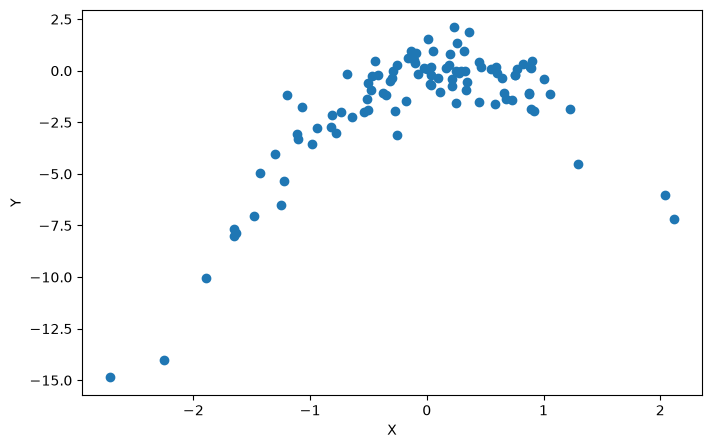

In [24]:
fig, ax = subplots(figsize=(8, 5))
ax.scatter(x, y)
ax.set_xlabel('X')
ax.set_ylabel('Y');

**Interpretation:** The relationship between $X$ and $Y$ is clearly non-linear: the points form an upside-down U (a parabola), with $Y$ largest near $X = 0$ and decreasing on both sides. This matches the quadratic model in (a).

### 8(c)
As in the ISLP lab, `np.power.outer(x, np.arange(d+1))` builds the columns $1, X, \dots, X^d$, and `cross_validate()` with `cv` equal to the number of observations gives LOOCV.

In [25]:
np.random.seed(1)
M = sklearn_sm(sm.OLS)
cv_error = np.zeros(4)
for i, d in enumerate(range(1, 5)):
    X = np.power.outer(x, np.arange(d + 1))
    M_CV = cross_validate(M, X, y, cv=x.shape[0])
    cv_error[i] = np.mean(M_CV['test_score'])
cv_error

array([6.63302984, 1.12293686, 1.30179655, 1.33239427])

LOOCV errors: 

| Model | LOOCV error |
|---|---|
| i. $Y = \beta_0 + \beta_1X + \epsilon$ | 6.633 |
| ii. $Y = \beta_0 + \beta_1X + \beta_2X^2 + \epsilon$ | 1.123 |
| iii. $Y = \beta_0 + \beta_1X + \beta_2X^2 + \beta_3X^3 + \epsilon$ | 1.302 |
| iv. $Y = \beta_0 + \beta_1X + \beta_2X^2 + \beta_3X^3 + \beta_4X^4 + \epsilon$ | 1.332 |

### 8(d)

In [26]:
np.random.seed(2)
cv_error2 = np.zeros(4)
for i, d in enumerate(range(1, 5)):
    X = np.power.outer(x, np.arange(d + 1))
    M_CV = cross_validate(M, X, y, cv=x.shape[0])
    cv_error2[i] = np.mean(M_CV['test_score'])
cv_error2

array([6.63302984, 1.12293686, 1.30179655, 1.33239427])

**Interpretation:** The results are exactly the same as in (c). LOOCV has no randomness in the training/validation splits: each observation is left out exactly once, so the $n$ fits are always the same no matter which seed is used.

### 8(e)
**Interpretation:** The quadratic model (ii) has the smallest LOOCV error (1.123). This is what I expected, because the true relationship in (a) is quadratic. As in Figure 5.4 of the book, there is a sharp drop in the estimated test MSE from the linear to the quadratic fit, and then no improvement from the higher-degree polynomials: the cubic and quartic terms only add variance, so their LOOCV errors are slightly higher.

### 8(f)
Fit each model by least squares on all the data. In the tables `const` is the intercept and `x1`, `x2`, `x3`, `x4` are $X, X^2, X^3, X^4$.

In [27]:
for d in range(1, 5):
    X = np.power.outer(x, np.arange(d + 1))
    results = sm.OLS(y, X).fit()
    print('Model with degree', d)
    print(summarize(results))
    print()

Model with degree 1
         coef  std err      t  P>|t|
const -1.4650    0.247 -5.937    0.0
x1     1.9494    0.289  6.752    0.0

Model with degree 2
         coef  std err       t  P>|t|
const -0.0728    0.119  -0.611  0.543
x1     0.9663    0.126   7.647  0.000
x2    -2.0047    0.091 -22.072  0.000

Model with degree 3
         coef  std err       t  P>|t|
const -0.0572    0.120  -0.477  0.635
x1     1.1146    0.187   5.945  0.000
x2    -2.0471    0.099 -20.673  0.000
x3    -0.0643    0.060  -1.070  0.287

Model with degree 4
         coef  std err       t  P>|t|
const  0.1008    0.136   0.743  0.460
x1     0.9050    0.205   4.423  0.000
x2    -2.5059    0.221 -11.336  0.000
x3     0.0338    0.073   0.466  0.642
x4     0.1042    0.045   2.309  0.023



**Interpretation:** In models (ii)–(iv), the $X$ and $X^2$ terms have p-values close to 0, so they are highly significant, and in model (ii) the estimates $\hat\beta_1 = 0.97$ and $\hat\beta_2 = -2.00$ are very close to the true values 1 and $-2$. The intercept is not significant in models (ii)–(iv), which matches the true $\beta_0 = 0$. The $X^3$ term is not significant in models (iii) and (iv). The $X^4$ term in model (iv) has p-value 0.023, just below 0.05; since $X^4$ is not in the true model, this is most likely due to chance, and model (iv) still has a higher LOOCV error than model (ii). So overall the significance tests agree with the cross-validation results: the linear and quadratic terms are the important ones, and the quadratic model is the best choice.

## Question 9
`Boston` data; `medv` is the median home value in \$1000s.

In [28]:
Boston = load_data('Boston')
Boston.shape

(506, 13)

### 9(a)

In [29]:
mu_hat = Boston['medv'].mean()
mu_hat

np.float64(22.532806324110677)

$\hat\mu = 22.53$, so the estimated population mean of `medv` is about \$22,530.

### 9(b)
Standard error of the sample mean: sample standard deviation divided by $\sqrt{n}$.

In [30]:
se_mu_hat = Boston['medv'].std() / np.sqrt(Boston.shape[0])
se_mu_hat

np.float64(0.40886114749753505)

**Interpretation:** $\text{SE}(\hat\mu) = 0.409$. This tells us roughly how far the sample mean would typically be from the true population mean if we repeated the sampling many times: about 0.41 (\$410). This is small compared with 22.53, so $\hat\mu$ is a precise estimate.

### 9(c)
Bootstrap with `boot_SE()` from the lab.

In [31]:
def mean_func(D, idx):
    return D['medv'].loc[idx].mean()

se_boot = boot_SE(mean_func, Boston, B=1000, seed=0)
se_boot

np.float64(0.41253476750888246)

**Interpretation:** The bootstrap estimate of $\text{SE}(\hat\mu)$ is 0.413, very close to the formula value 0.409 from (b).

### 9(d)
Approximate 95% confidence interval $[\hat\mu - 2\text{SE}(\hat\mu),\ \hat\mu + 2\text{SE}(\hat\mu)]$.

In [32]:
print('Bootstrap:', round(mu_hat - 2 * se_boot, 3), 'to', round(mu_hat + 2 * se_boot, 3))
print('Formula  :', round(mu_hat - 2 * se_mu_hat, 3), 'to', round(mu_hat + 2 * se_mu_hat, 3))

Bootstrap: 21.708 to 23.358
Formula  : 21.715 to 23.351


**Interpretation:** The bootstrap interval is [21.71, 23.36] and the interval using `Boston['medv'].std()` is [21.72, 23.35]. The two are almost identical, so we can be about 95% confident that the true mean of `medv` lies between about \$21,700 and \$23,400.

### 9(e)

In [33]:
mu_med = Boston['medv'].median()
mu_med

np.float64(21.2)

$\hat\mu_{med} = 21.2$. The median is a bit below the mean, because a few very expensive tracts pull the mean up.

### 9(f)

In [34]:
def median_func(D, idx):
    return D['medv'].loc[idx].median()

boot_SE(median_func, Boston, B=1000, seed=0)

np.float64(0.36944622071302163)

**Interpretation:** The bootstrap estimate of $\text{SE}(\hat\mu_{med})$ is 0.369. There is no simple formula for the standard error of the median, but the bootstrap gives one easily. The standard error is small compared with the median of 21.2, so the median is also estimated precisely.

### 9(g)

In [35]:
mu_01 = np.percentile(Boston['medv'], 10)
mu_01

np.float64(12.75)

$\hat\mu_{0.1} = 12.75$: about 10% of Boston census tracts have a median home value below \$12,750.

### 9(h)

In [36]:
def p10_func(D, idx):
    return np.percentile(D['medv'].loc[idx], 10)

boot_SE(p10_func, Boston, B=1000, seed=0)

np.float64(0.5034541091295026)

**Interpretation:** The bootstrap estimate of $\text{SE}(\hat\mu_{0.1})$ is 0.503. This is still small relative to 12.75, so the 10th percentile is estimated fairly precisely. It is larger than the standard errors of the mean (0.41) and median (0.37), because a percentile in the tail depends on fewer observations and so varies more from one bootstrap sample to another.

## Additional Question: 10-fold cross-validation on the simulated data
This question uses **$K$-fold cross-validation** on the simulated data from Question 8.

(a) Use 10-fold cross-validation to estimate the test MSE of the four models (i)–(iv) from Question 8(c).

(b) Repeat (a) with three other random seeds. Do the results change? Why?

(c) Compare the 10-fold CV results with the LOOCV results from Question 8(c). Which model would you choose, and which method would you prefer here?

### Additional (a)
As in the ISLP lab, `KFold(n_splits=10, shuffle=True, random_state=0)` randomly splits the 100 observations into 10 folds of 10. The same folds are used for every model, so the comparison between models is fair. The CV estimate is

$$\text{CV}_{(10)} = \frac{1}{10}\sum_{i=1}^{10}\text{MSE}_i.$$

In [37]:
cv = KFold(n_splits=10,
           shuffle=True,
           random_state=0)
cv_error_10 = np.zeros(4)
for i, d in enumerate(range(1, 5)):
    X = np.power.outer(x, np.arange(d + 1))
    M_CV = cross_validate(M, X, y, cv=cv)
    cv_error_10[i] = np.mean(M_CV['test_score'])
cv_error_10

array([6.65207021, 1.12268047, 1.4835268 , 1.48088686])

**Answer:** With `random_state=0`, the 10-fold CV estimates of the test MSE are 6.652 (linear), 1.123 (quadratic), 1.484 (cubic) and 1.481 (quartic). As with LOOCV, the quadratic model has the lowest estimated test error and the linear model is much worse.

### Additional (b)

In [38]:
for seed in [1, 2, 3]:
    cv = KFold(n_splits=10,
               shuffle=True,
               random_state=seed)
    errors = np.zeros(4)
    for i, d in enumerate(range(1, 5)):
        X = np.power.outer(x, np.arange(d + 1))
        M_CV = cross_validate(M, X, y, cv=cv)
        errors[i] = np.mean(M_CV['test_score'])
    print('Seed', seed, ':', np.round(errors, 4))

Seed 1 : [6.6018 1.148  1.3188 1.2832]
Seed 2 : [6.3615 1.1819 1.2947 1.2021]
Seed 3 : [6.4827 1.1522 1.2737 1.2442]


**Answer:** Yes, the numbers change with the seed. For example, the quadratic model's error is 1.148, 1.182 and 1.152 for seeds 1, 2 and 3, and the cubic model's error moves between 1.274 and 1.319. This is because $K$-fold CV randomly assigns observations to folds, so a different seed gives different folds and different training sets. This is different from Question 8(d), where LOOCV gave exactly the same result for any seed. Even so, the conclusion does not change: in every case the linear model is far worse, and the quadratic model has the lowest error.

### Additional (c)

In [39]:
print('LOOCV       :', np.round(cv_error, 4))
print('10-fold CV  :', np.round(cv_error_10, 4))

LOOCV       : [6.633  1.1229 1.3018 1.3324]
10-fold CV  : [6.6521 1.1227 1.4835 1.4809]


**Answer:** Both methods choose the quadratic model (ii), which is the true model, and both show the sharp drop in error from the linear to the quadratic fit, then no improvement from higher-degree terms. The two methods give similar values for the linear and quadratic models. 10-fold CV needed only 10 fits per model instead of 100. Each 10-fold training set has 90 observations instead of 99, so 10-fold CV has a little more bias, but the training sets overlap less, so it usually has lower variance. As the book explains, $k = 5$ or $k = 10$ is a good balance in this bias-variance trade-off. For this small data set both methods are quick and lead to the same choice. For a larger data set, I would prefer 10-fold CV because of the lower computational cost.

---
**AI-use disclosure:** AI was used to debug the code, to write the mathematical formulation, and to review some analysis questions.